In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, classification_report)

sns.set_theme(style="whitegrid", font_scale=1.05)
ON_TIME, LATE = "#2a9d8f", "#e76f51"
RANDOM_STATE = 42

In [2]:
FILE = "indian_ecommerce_powerbi_dataset.xlsx"


from google.colab import files
files.upload()

orders    = pd.read_excel(FILE, sheet_name="Orders")
customers = pd.read_excel(FILE, sheet_name="Customers")

print("Orders   :", orders.shape)
print("Customers:", customers.shape)
orders.head()

Saving indian_ecommerce_powerbi_dataset.xlsx to indian_ecommerce_powerbi_dataset.xlsx
Orders   : (5000, 26)
Customers: (2781, 6)


,OrderID,OrderDate,CustomerID,ProductID,ProductName,Category,Subcategory,Quantity,UnitPriceINR,DiscountPercent,...,City,State,PromisedDeliveryDate,DeliveryDate,DeliveryDays,LateDays,Year,MonthNumber,MonthName,Quarter
0,IN-2025-000001,2025-02-02,CUST-00851,PRD-003,AeroCool Mixer Grinder,Electronics,Home Appliances,1,4934,5,...,Patna,Bihar,2025-02-05,NaT,NaN,0,2025,2,Feb,Q1
1,IN-2025-000002,2025-10-10,CUST-00082,PRD-011,StackRight Storage Boxes,Home & Kitchen,Storage,1,1329,0,...,Siliguri,West Bengal,2025-10-14,2025-10-12,2.0,0,2025,10,Oct,Q4
2,IN-2025-000003,2025-08-27,CUST-00016,PRD-011,StackRight Storage Boxes,Home & Kitchen,Storage,1,1329,5,...,Kochi,Kerala,2025-08-29,2025-09-01,5.0,3,2025,8,Aug,Q3
3,IN-2025-000004,2025-06-10,CUST-00852,PRD-007,MasalaCraft Mixer Set,Home & Kitchen,Kitchen,1,2242,10,...,Delhi,Delhi,2025-06-15,2025-06-15,5.0,0,2025,6,Jun,Q2
4,IN-2025-000005,2025-06-08,CUST-03113,PRD-016,FestiveSilk Saree,Fashion,Ethnic Wear,1,6653,20,...,Thiruvananthapuram,Kerala,2025-06-11,2025-06-13,5.0,2,2025,6,Jun,Q2


In [8]:
'-----------OrderId-----------',orders.dtypes ,'---------customers-----' , customers.dtypes

('-----------OrderId-----------',
 OrderID                         object
 OrderDate               datetime64[ns]
 CustomerID                      object
 ProductID                       object
 ProductName                     object
 Category                        object
 Subcategory                     object
 Quantity                         int64
 UnitPriceINR                     int64
 DiscountPercent                  int64
 DiscountINR                    float64
 ShippingFeeINR                   int64
 SalesINR                       float64
 PaymentMethod                   object
 OrderStatus                     object
 Region                          object
 City                            object
 State                           object
 PromisedDeliveryDate    datetime64[ns]
 DeliveryDate            datetime64[ns]
 DeliveryDays                   float64
 LateDays                         int64
 Year                             int64
 MonthNumber                      int64
 Month

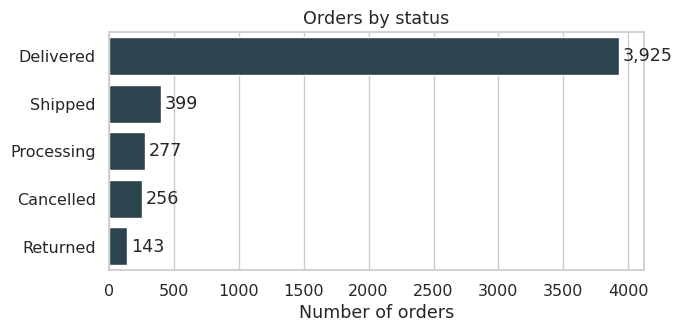

In [3]:
status = orders["OrderStatus"].value_counts()

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=status.values, y=status.index, color="#264653", ax=ax)
for i, v in enumerate(status.values):
    ax.text(v + 30, i, f"{v:,}", va="center")
ax.set_title("Orders by status"); ax.set_xlabel("Number of orders"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [9]:
df = orders[orders["OrderStatus"] == "Delivered"].merge(
        customers[["CustomerID", "CustomerSegment", "LoyaltyPoints"]],
        on="CustomerID", how="left")


df["Late"] = (df["LateDays"] > 0).astype(int)


df["PromisedDays"] = (df["PromisedDeliveryDate"] - df["OrderDate"]).dt.days
df["OrderMonth"]   = df["OrderDate"].dt.month
df["OrderWeekday"] = df["OrderDate"].dt.day_name()

print(f"Delivered orders used: {len(df):,}")
print(f"Late rate: {df['Late'].mean():.1%}   (so ~half of orders are late)")
df[["OrderID", "PromisedDays", "Category", "Region", "PaymentMethod", "Late"]].head()

Delivered orders used: 3,925
Late rate: 50.4%   (so ~half of orders are late)


,OrderID,PromisedDays,Category,Region,PaymentMethod,Late
0,IN-2025-000002,4,Home & Kitchen,East,Debit Card,0
1,IN-2025-000003,2,Home & Kitchen,South,Cash on Delivery,1
2,IN-2025-000004,5,Home & Kitchen,North,Credit Card,0
3,IN-2025-000005,3,Fashion,South,Debit Card,1
4,IN-2025-000006,5,Home & Kitchen,Central,UPI,0


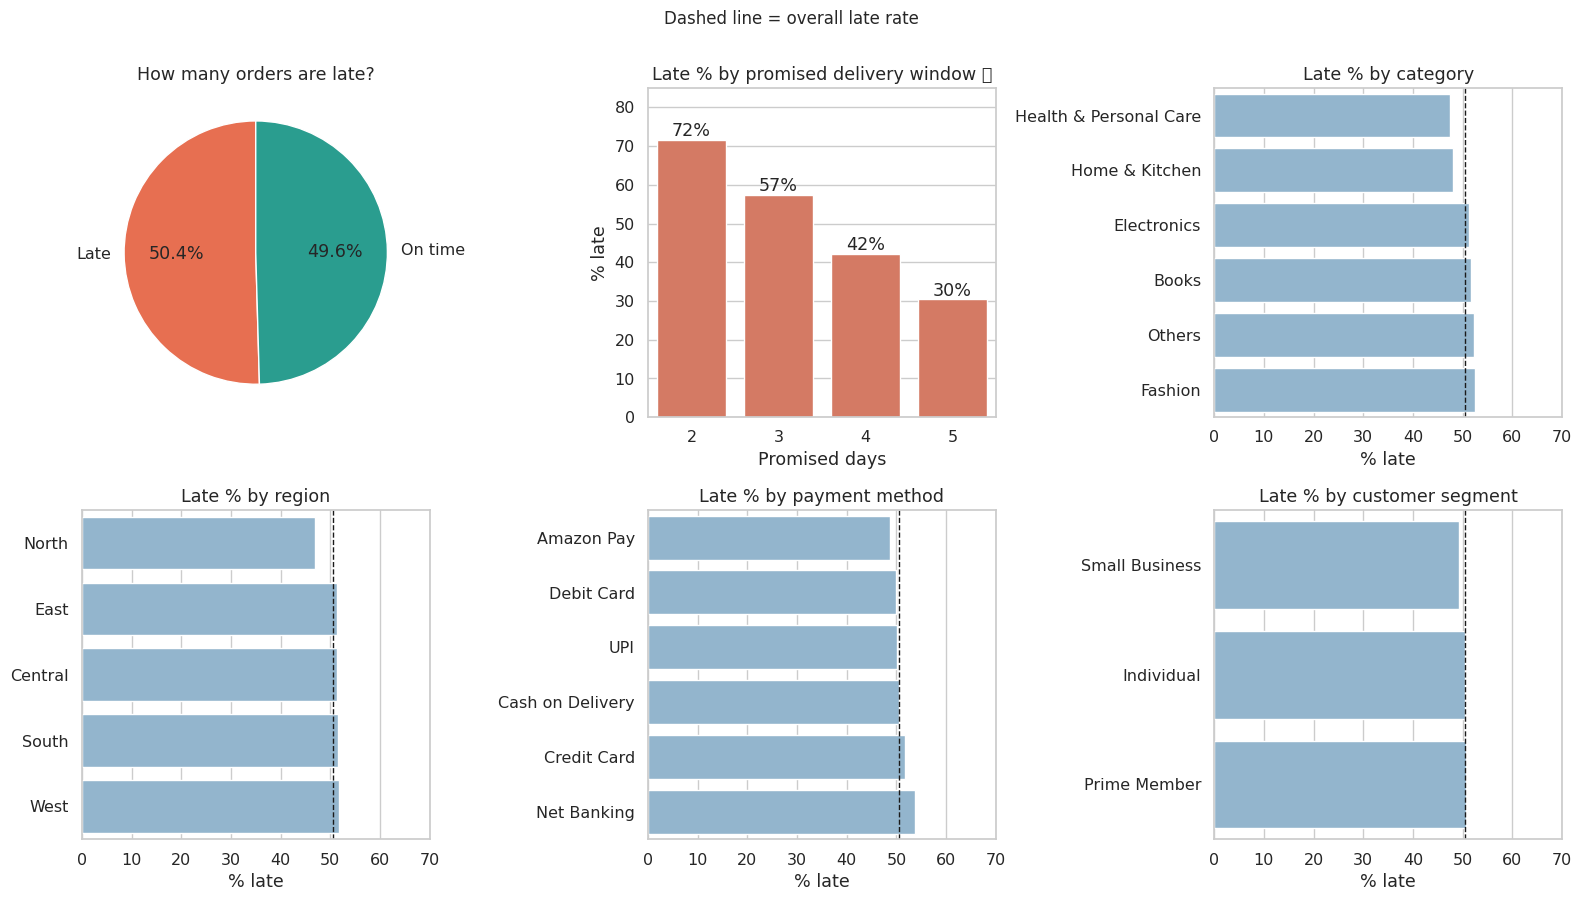

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))


c = df["Late"].map({0: "On time", 1: "Late"}).value_counts()
axes[0, 0].pie(c.values, labels=c.index, autopct="%1.1f%%", startangle=90,
               colors=[LATE if i == "Late" else ON_TIME for i in c.index])
axes[0, 0].set_title("How many orders are late?")


r = df.groupby("PromisedDays")["Late"].mean() * 100
sns.barplot(x=r.index, y=r.values, color=LATE, ax=axes[0, 1])
for i, v in enumerate(r.values): axes[0, 1].text(i, v + 1, f"{v:.0f}%", ha="center")
axes[0, 1].set_title("Late % by promised delivery window ⭐")
axes[0, 1].set_xlabel("Promised days")
axes[0, 1].set_ylabel("% late")
axes[0, 1].set_ylim(0, 85)


def rate_plot(col, ax, title, order=None):
    r = (df.groupby(col)["Late"].mean() * 100).sort_values()
    sns.barplot(x=r.values, y=r.index, color="#8ab6d6", ax=ax, order=order or r.index)
    ax.axvline(df["Late"].mean() * 100, color="k", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("% late"); ax.set_ylabel("")
    ax.set_xlim(0, 70)

rate_plot("Category", axes[0, 2], "Late % by category")
rate_plot("Region", axes[1, 0], "Late % by region")
rate_plot("PaymentMethod", axes[1, 1], "Late % by payment method")
rate_plot("CustomerSegment", axes[1, 2], "Late % by customer segment")

plt.suptitle("Dashed line = overall late rate", y=1.0, fontsize=12)
plt.tight_layout()
plt.show()

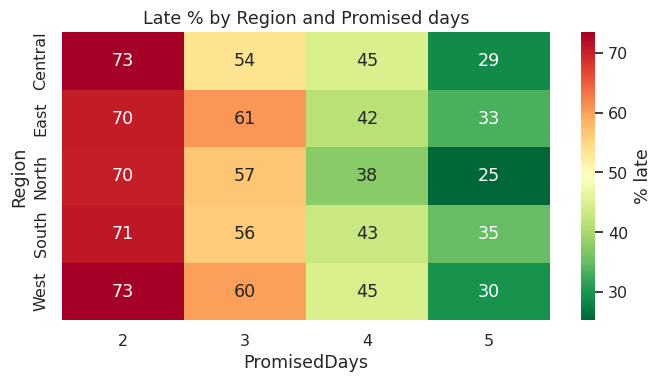

In [18]:

pivot = df.pivot_table(index="Region", columns="PromisedDays", values="Late", aggfunc="mean") * 100

plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn_r", cbar_kws={"label": "% late"})
plt.title("Late % by Region and Promised days"); plt.tight_layout(); plt.show()

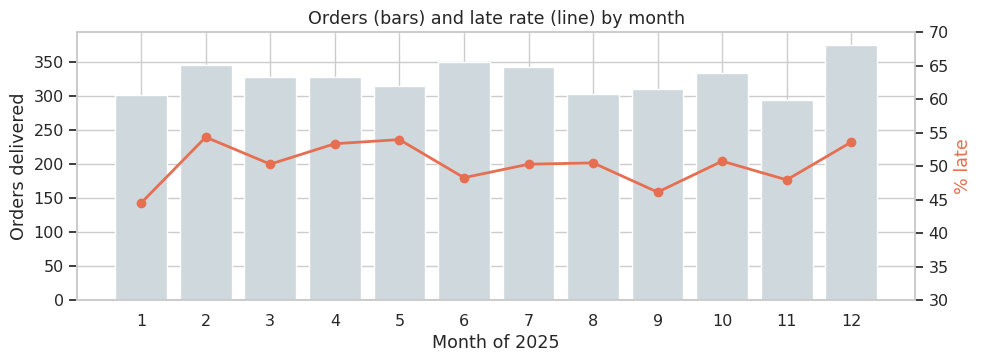

In [23]:

m = df.groupby("OrderMonth").agg(orders=("Late", "size"), late_pct=("Late", "mean"))
m["late_pct"] *= 100

fig, ax1 = plt.subplots(figsize=(10, 3.8))
ax1.bar(m.index, m["orders"], color="#cfd8dc"); ax1.set_ylabel("Orders delivered"); ax1.set_xlabel("Month of 2025")
ax2 = ax1.twinx()
ax2.plot(m.index, m["late_pct"], color=LATE, marker="o", lw=2)
ax2.set_ylabel("% late", color=LATE)
ax2.set_ylim(30, 70); ax2.grid(False)
plt.title("Orders (bars) and late rate (line) by month")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [24]:
numeric_cols     = ["PromisedDays", "Quantity", "UnitPriceINR", "DiscountPercent",
                    "ShippingFeeINR", "LoyaltyPoints", "OrderMonth"]
categorical_cols = ["Category", "Region", "PaymentMethod", "CustomerSegment", "OrderWeekday"]

X = df[numeric_cols + categorical_cols]
y = df["Late"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
], remainder="passthrough")

print(f"Train: {len(X_train):,} orders | Test: {len(X_test):,} orders")
print(f"Late rate  train: {y_train.mean():.1%}  |  test: {y_test.mean():.1%}")

Train: 2,943 orders | Test: 982 orders
Late rate  train: 50.5%  |  test: 50.4%


In [39]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

tree = Pipeline([("prep", preprocess),
                 ("model", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]).fit(X_train, y_train)

forest = Pipeline([("prep", preprocess),
                   ("model", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10,
                                                    random_state=RANDOM_STATE, n_jobs=-1))]).fit(X_train, y_train)
print("Models trained ")

Models trained 


,Accuracy,ROC-AUC
Model,,
Baseline (guess),0.504,0.500
Decision Tree,0.614,0.648
Random Forest,0.616,0.634


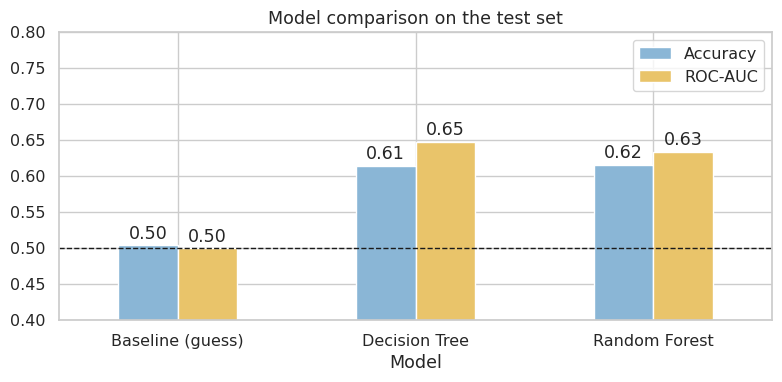

In [26]:
models = {"Baseline (guess)": baseline, "Decision Tree": tree, "Random Forest": forest}

rows = []
for name, mdl in models.items():
    pred  = mdl.predict(X_test)
    proba = mdl.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index("Model")
display(results.style.format("{:.3f}").background_gradient(cmap="Greens"))

ax = results.plot.bar(figsize=(8, 4), color=["#8ab6d6", "#e9c46a"], rot=0)
ax.set_title("Model comparison on the test set")
ax.set_ylim(0.4, 0.8)
ax.axhline(0.5, color="k", ls="--", lw=1)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", padding=2)
plt.tight_layout()
plt.show()

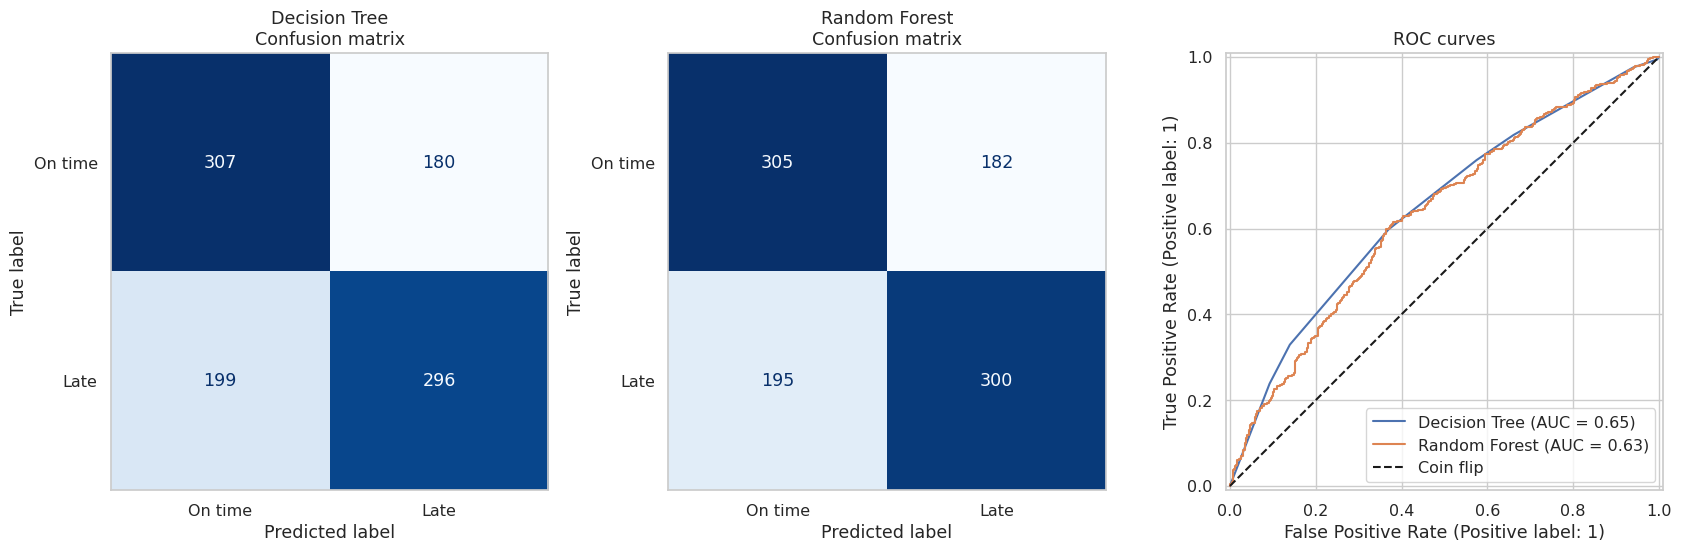

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 9))


for ax, (name, mdl) in zip(axes[:2], [("Decision Tree", tree), ("Random Forest", forest)]):
    ConfusionMatrixDisplay.from_estimator(mdl, X_test, y_test, display_labels=["On time", "Late"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}\nConfusion matrix"); ax.grid(False)


for name, mdl in [("Decision Tree", tree), ("Random Forest", forest)]:
    RocCurveDisplay.from_estimator(mdl, X_test, y_test, name=name, ax=axes[2])
axes[2].plot([0, 1], [0, 1], "k--", label="Coin flip")
axes[2].set_title("ROC curves"); axes[2].legend(loc="lower right")

plt.tight_layout(); plt.show()

In [30]:
print("Random Forest: detailed report\n")
print(classification_report(y_test, forest.predict(X_test), target_names=["On time", "Late"]))

Random Forest: detailed report

              precision    recall  f1-score   support

     On time       0.61      0.63      0.62       487
        Late       0.62      0.61      0.61       495

    accuracy                           0.62       982
   macro avg       0.62      0.62      0.62       982
weighted avg       0.62      0.62      0.62       982



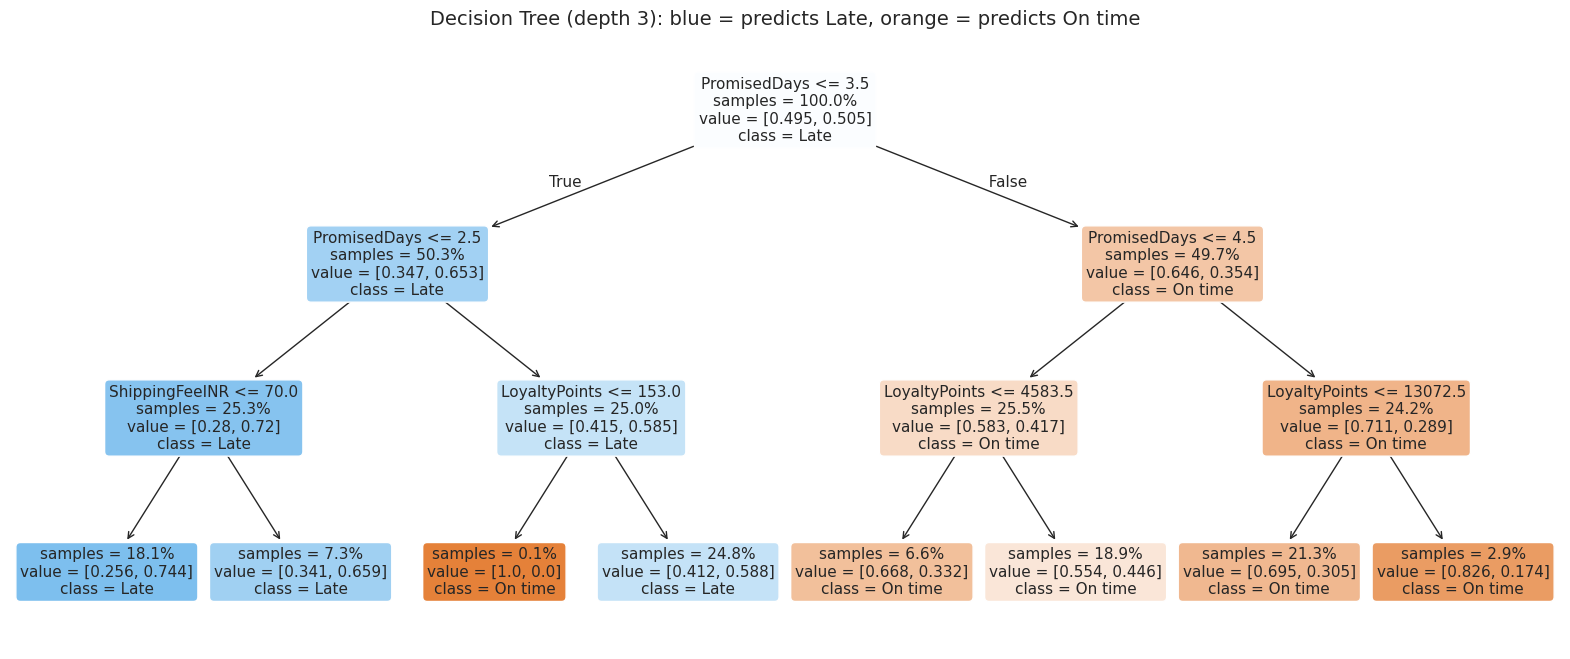

In [31]:
feature_names = tree.named_steps["prep"].get_feature_names_out()
feature_names = [n.replace("cat__", "").replace("remainder__", "") for n in feature_names]

plt.figure(figsize=(20, 8))
plot_tree(tree.named_steps["model"], feature_names=feature_names, class_names=["On time", "Late"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=11)
plt.title("Decision Tree (depth 3): blue = predicts Late, orange = predicts On time", fontsize=14)
plt.show()

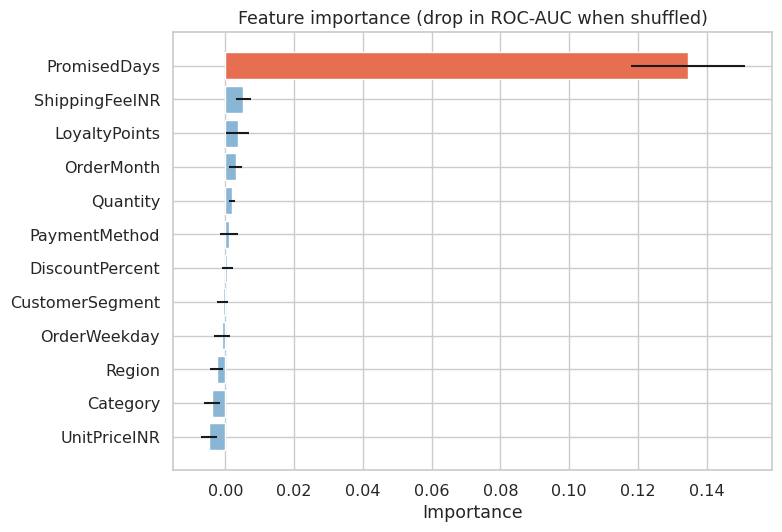

In [32]:
perm = permutation_importance(forest, X_test, y_test, scoring="roc_auc",
                              n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(imp.index, imp.values, xerr=pd.Series(perm.importances_std, index=X_test.columns)[imp.index],
        color=[LATE if v == imp.max() else "#8ab6d6" for v in imp.values])
ax.set_title("Feature importance (drop in ROC-AUC when shuffled)")
ax.set_xlabel("Importance"); plt.tight_layout(); plt.show()

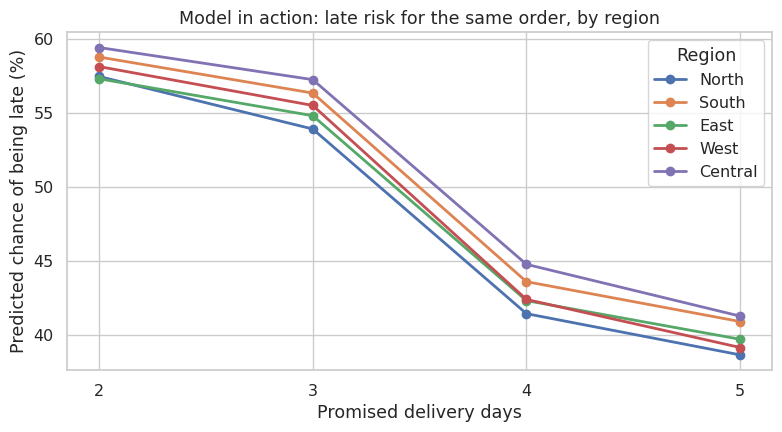

Example: Electronics order to the North, 2-day promise → 57% chance of being late
Same order with a 5-day promise                        → 39% chance of being late


In [35]:
def late_risk(promised_days, category="Electronics", region="North", payment="UPI",
              segment="Individual", qty=1, price=2500, discount=10, shipping=60,
              loyalty=5000, month=6, weekday="Monday"):
    order = pd.DataFrame([{
        "PromisedDays": promised_days, "Quantity": qty, "UnitPriceINR": price,
        "DiscountPercent": discount, "ShippingFeeINR": shipping, "LoyaltyPoints": loyalty,
        "OrderMonth": month, "Category": category, "Region": region,
        "PaymentMethod": payment, "CustomerSegment": segment, "OrderWeekday": weekday}])
    return forest.predict_proba(order)[0, 1]

days = [2, 3, 4, 5]
risk = {r: [late_risk(d, region=r) for d in days] for r in ["North", "South", "East", "West", "Central"]}

fig, ax = plt.subplots(figsize=(8, 4.5))
for r, v in risk.items():
    ax.plot(days, [x * 100 for x in v], marker="o", lw=2, label=r)
ax.set_xticks(days); ax.set_xlabel("Promised delivery days"); ax.set_ylabel("Predicted chance of being late (%)")
ax.set_title("Model in action: late risk for the same order, by region"); ax.legend(title="Region")
plt.tight_layout(); plt.show()

print(f"Example: Electronics order to the North, 2-day promise → {late_risk(2):.0%} chance of being late")
print(f"Same order with a 5-day promise                        → {late_risk(5):.0%} chance of being late")

In [36]:
test_view = X_test.copy()
test_view["P(late)"] = forest.predict_proba(X_test)[:, 1]
test_view["Actually late?"] = y_test.map({0: "No", 1: "Yes"})
top = test_view.sort_values("P(late)", ascending=False).head(10)
top[["PromisedDays", "Category", "Region", "PaymentMethod", "P(late)", "Actually late?"]].style.format({"P(late)": "{:.0%}"})

,PromisedDays,Category,Region,PaymentMethod,P(late),Actually late?
1658,2,Home & Kitchen,Central,Credit Card,66%,Yes
757,2,Others,Central,Credit Card,66%,Yes
3056,2,Fashion,East,Credit Card,64%,No
2175,2,Fashion,Central,UPI,64%,No
1525,2,Fashion,Central,Net Banking,64%,Yes
2083,2,Others,Central,UPI,64%,Yes
1495,2,Home & Kitchen,East,Debit Card,64%,No
2688,2,Electronics,Central,UPI,64%,Yes
2461,2,Electronics,Central,UPI,64%,Yes
1780,2,Electronics,East,Credit Card,64%,Yes


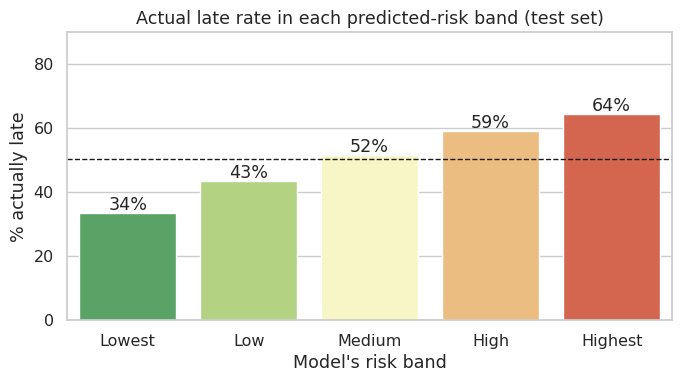

In [37]:
test_view["Risk band"] = pd.qcut(test_view["P(late)"], 5, labels=["Lowest", "Low", "Medium", "High", "Highest"])
band = test_view.assign(Late=y_test).groupby("Risk band", observed=True)["Late"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=band.index, y=band.values, palette="RdYlGn_r", ax=ax)
for i, v in enumerate(band.values): ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.axhline(y_test.mean() * 100, color="k", ls="--", lw=1)
ax.set_title("Actual late rate in each predicted-risk band (test set)")
ax.set_ylabel("% actually late"); ax.set_xlabel("Model's risk band"); ax.set_ylim(0, 90)
plt.tight_layout(); plt.show()

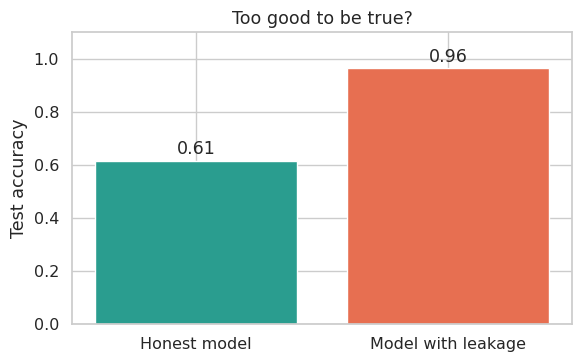

In [38]:
X_leak = df[numeric_cols + categorical_cols + ["DeliveryDays"]]
Xl_train, Xl_test, yl_train, yl_test = train_test_split(X_leak, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

leaky_prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)], remainder="passthrough")
leaky = Pipeline([("prep", leaky_prep),
                  ("model", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))]).fit(Xl_train, yl_train)

acc_leaky = accuracy_score(yl_test, leaky.predict(Xl_test))
acc_honest = accuracy_score(y_test, tree.predict(X_test))

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(["Honest model", "Model with leakage"], [acc_honest, acc_leaky], color=[ON_TIME, LATE])
ax.bar_label(bars, fmt="%.2f", padding=2); ax.set_ylim(0, 1.1); ax.set_ylabel("Test accuracy")
ax.set_title("Too good to be true?"); plt.tight_layout(); plt.show()